# 🚗 Team 53 — Machine Learning Based Lifecycle Intelligence System
### Automotive Material Lifecycle Prediction Pipeline

---

**Project Overview:**  
This notebook implements a full ML pipeline to predict the lifecycle disposition of automotive materials (Recycle / Reuse / Dispose).

**Phases covered:**
1. 📦 Dataset Loading & Audit
2. 🧹 Preprocessing & Cleaning
3. 🔢 Feature Encoding
4. ✂️ Train / Validation / Test Split (70% / 10% / 20%)
5. 🤖 Model Training — RF, XGBoost, SVM, Hybrid Stacking
6. 📊 Hyperparameter Tuning (GridSearchCV)
7. 📈 Epoch / Boosting-round tracking (XGBoost)
8. 🏆 Model Comparison & Final Test Evaluation
9. 💾 Results Export to ../results/

> **Evaluator feedback addressed:** remove missing rows · 70/20/10 split · multiple algorithms including hybrid · learning rate + epoch tracking · validation loss & accuracy plotted · GridSearchCV tuning

---
## 📚 Cell 0 — Imports & Global Settings

In [1]:
import os
import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, log_loss, ConfusionMatrixDisplay
)
from xgboost import XGBClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': 0.3, 'font.size': 11})
sns.set_style('whitegrid')

# All outputs go to the results folder
NOTEBOOK_DIR = os.path.dirname(os.path.abspath('__file__'))
RESULTS_DIR = os.path.join('..', 'results')
os.makedirs(RESULTS_DIR, exist_ok=True)

print('✅ All imports successful')
print(f'NumPy: {np.__version__} | Pandas: {pd.__version__}')

✅ All imports successful
NumPy: 2.0.2 | Pandas: 2.3.3


---
## 📦 Cell 1 — Load Dataset

In [2]:
DATA_PATH = os.path.join('..', 'data', 'automotive_material_lifecycle_dataset.csv')

df_raw = pd.read_csv(DATA_PATH)

print(f'📊 Raw dataset shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns')
df_raw.head(5)

📊 Raw dataset shape: 1,800 rows × 20 columns


,Material Name,Vehicle Type,Component,Manufacturing Year,Weight,Carbon Footprint (kg CO2 eq),Recycling Efficiency (%),Hazardous Level,Material Condition,Tensile Strength (MPa),Thermal Resistance (°C),Recycled Content (%),CO2 Abatement Cost ($/ton),Material Cost ($/kg),Supply Chain Risk Index,Durability Index,Toxicity Index,Energy Consumption (MJ/kg),Corrosion Resistance,Target
0,Polyurethane (PU),ICE,Dashboard,2020,17.356292,NaN,21.674172,High,Good,18.571670,106.035539,5.846174,235.519804,3.407829,4,3,51.937003,98.524445,Medium,Dispose
1,Polyethylene (HDPE),Electric,Fuel Tank,2020,12.997219,23.249774,26.655427,Low,Poor,21.359097,122.367720,14.561550,237.484633,1.720087,3,7,10.466657,78.606151,High,Recycle
2,Polyurethane (PU),Hybrid,Dashboard,2023,17.700768,98.255742,17.440765,High,Good,27.379423,81.375541,18.639806,161.404797,2.993783,4,4,46.092275,95.602041,Medium,Dispose
3,Structural Steel,Hybrid,Chassis,2011,210.884554,449.202749,76.265408,Low,Fair,514.088795,1304.166852,68.446881,89.117369,1.323124,4,8,14.266589,28.801267,Medium,Dispose
4,Polyethylene (HDPE),Electric,Fuel Tank,2022,6.491013,11.288371,71.309229,Low,Excellent,30.602860,124.580143,24.281759,101.106698,1.622619,3,7,19.868869,82.000772,High,Reuse


---
## 🔍 Cell 2 — Dataset Audit

In [3]:
# 2a. Schema & dtypes
print('=' * 60)
print('COLUMN INFO')
print('=' * 60)
df_raw.info()

COLUMN INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 20 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Material Name                 1800 non-null   object 
 1   Vehicle Type                  1800 non-null   object 
 2   Component                     1800 non-null   object 
 3   Manufacturing Year            1800 non-null   int64  
 4   Weight                        1764 non-null   float64
 5   Carbon Footprint (kg CO2 eq)  1764 non-null   float64
 6   Recycling Efficiency (%)      1764 non-null   float64
 7   Hazardous Level               1800 non-null   object 
 8   Material Condition            1800 non-null   object 
 9   Tensile Strength (MPa)        1764 non-null   float64
 10  Thermal Resistance (°C)       1764 non-null   float64
 11  Recycled Content (%)          1800 non-null   float64
 12  CO2 Abatement Cost ($/ton)    1764 non-null   floa

In [4]:
# 2b. Missing values
missing = df_raw.isnull().sum()
missing_pct = (missing / len(df_raw) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing Count', ascending=False)

print(f'Total rows with at least one NaN: {df_raw.isnull().any(axis=1).sum()}')
print(f'Columns with NaN:')
display(missing_df)

Total rows with at least one NaN: 201
Columns with NaN:


,Missing Count,Missing %
Weight,36,2.0
Carbon Footprint (kg CO2 eq),36,2.0
Recycling Efficiency (%),36,2.0
Tensile Strength (MPa),36,2.0
Thermal Resistance (°C),36,2.0
CO2 Abatement Cost ($/ton),36,2.0


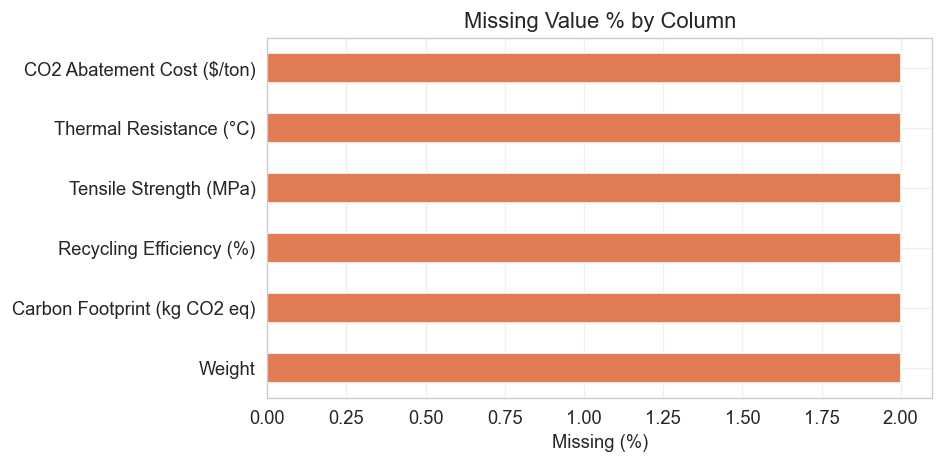

In [5]:
# 2c. Visualise missing values
if len(missing_df) > 0:
    fig, ax = plt.subplots(figsize=(8, 4))
    missing_df['Missing %'].plot(kind='barh', ax=ax, color='#E07B54')
    ax.set_xlabel('Missing (%)')
    ax.set_title('Missing Value % by Column')
    plt.tight_layout()
    plt.show()
else:
    print('✅ No missing values found!')

In [6]:
# 2d. Descriptive statistics (numeric)
print('Descriptive Statistics (Numeric Features):')
df_raw.describe().round(3)

Descriptive Statistics (Numeric Features):


,Manufacturing Year,Weight,Carbon Footprint (kg CO2 eq),Recycling Efficiency (%),Tensile Strength (MPa),Thermal Resistance (°C),Recycled Content (%),CO2 Abatement Cost ($/ton),Material Cost ($/kg),Supply Chain Risk Index,Durability Index,Toxicity Index,Energy Consumption (MJ/kg)
count,1800.000,1764.000,1764.000,1764.000,1764.000,1764.000,1800.000,1764.000,1800.000,1800.000,1800.000,1800.000,1800.000
mean,2017.293,48.254,296.493,56.730,228.573,485.118,27.973,151.236,3.557,4.884,6.608,25.379,80.769
std,4.558,91.441,686.201,27.332,369.844,447.119,16.036,92.024,4.244,1.813,1.879,15.919,57.836
min,2010.000,3.102,8.665,5.000,15.028,70.355,0.007,30.305,0.801,2.000,3.000,5.014,15.005
25%,2013.000,9.139,23.938,33.733,30.903,100.510,14.962,92.448,1.520,3.000,5.000,12.047,32.518
50%,2017.000,13.877,41.384,58.742,65.737,203.268,25.243,142.094,2.341,5.000,7.000,19.267,73.432
75%,2021.000,28.561,202.465,82.262,304.070,833.391,39.315,198.207,3.258,6.000,8.000,41.031,101.427
max,2025.000,1357.438,8560.100,98.000,5259.436,1398.516,69.619,1543.833,29.820,9.000,10.000,59.936,299.715


In [7]:
# 2e. Categorical feature distributions
cat_cols = df_raw.select_dtypes(include='object').columns.tolist()
print(f'Categorical columns: {cat_cols}\n')
for col in cat_cols:
    print(f'--- {col} ---')
    print(df_raw[col].value_counts().to_string())
    print()

Categorical columns: ['Material Name', 'Vehicle Type', 'Component', 'Hazardous Level', 'Material Condition', 'Corrosion Resistance', 'Target']

--- Material Name ---
Material Name
Structural Steel                          284
Polyurethane (PU)                         265
Aluminum Alloy (6061)                     210
Glass                                     196
Copper Alloy                              188
Acrylonitrile Butadiene Styrene (ABS)     169
Natural Rubber                            169
Polypropylene (PP)                        136
Polyethylene (HDPE)                       119
Carbon Fiber Reinforced Polymer (CFRP)     64

--- Vehicle Type ---
Vehicle Type
Hybrid      629
ICE         587
Electric    584

--- Component ---
Component
Windshield        196
Seat Foam         195
Dashboard         189
Wiring Harness    188
Bumper            186
Fuel Tank         181
Tires             169
Engine Block      168
Chassis           167
Body Panels       161

--- Hazardous Level ---
Haz

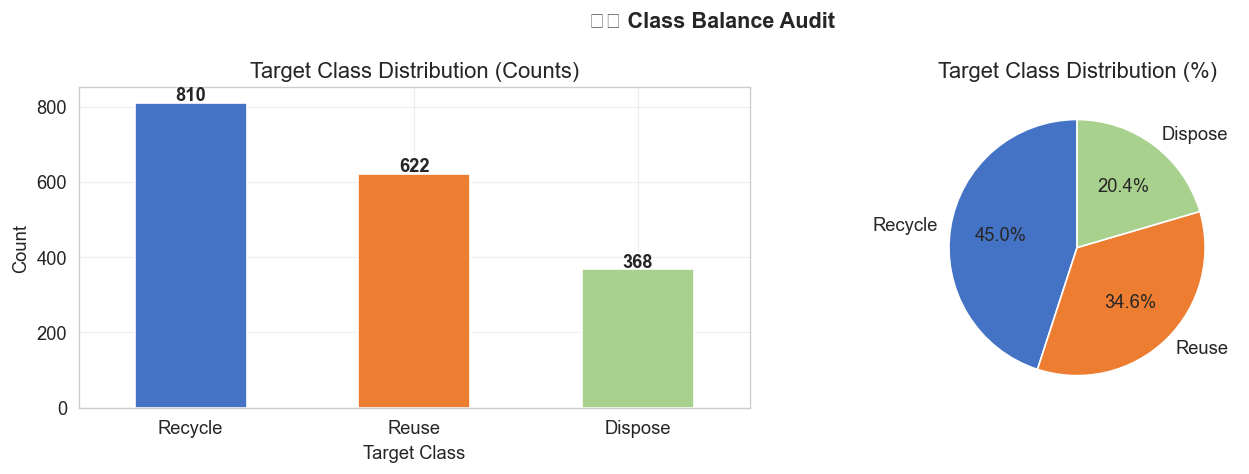

Target
Recycle    810
Reuse      622
Dispose    368
Name: count, dtype: int64

Class imbalance ratio (max/min): 2.20x


In [8]:
# 2f. Target class distribution
target_counts = df_raw['Target'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = ['#4472C4', '#ED7D31', '#A9D18E']
target_counts.plot(kind='bar', ax=axes[0], color=colors, edgecolor='white')
axes[0].set_title('Target Class Distribution (Counts)')
axes[0].set_xlabel('Target Class')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=0)
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 5, str(v), ha='center', fontweight='bold')

target_counts.plot(kind='pie', ax=axes[1], colors=colors, autopct='%1.1f%%', startangle=90)
axes[1].set_ylabel('')
axes[1].set_title('Target Class Distribution (%)')

plt.suptitle('⚖️ Class Balance Audit', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(target_counts)
print(f'\nClass imbalance ratio (max/min): {target_counts.max()/target_counts.min():.2f}x')

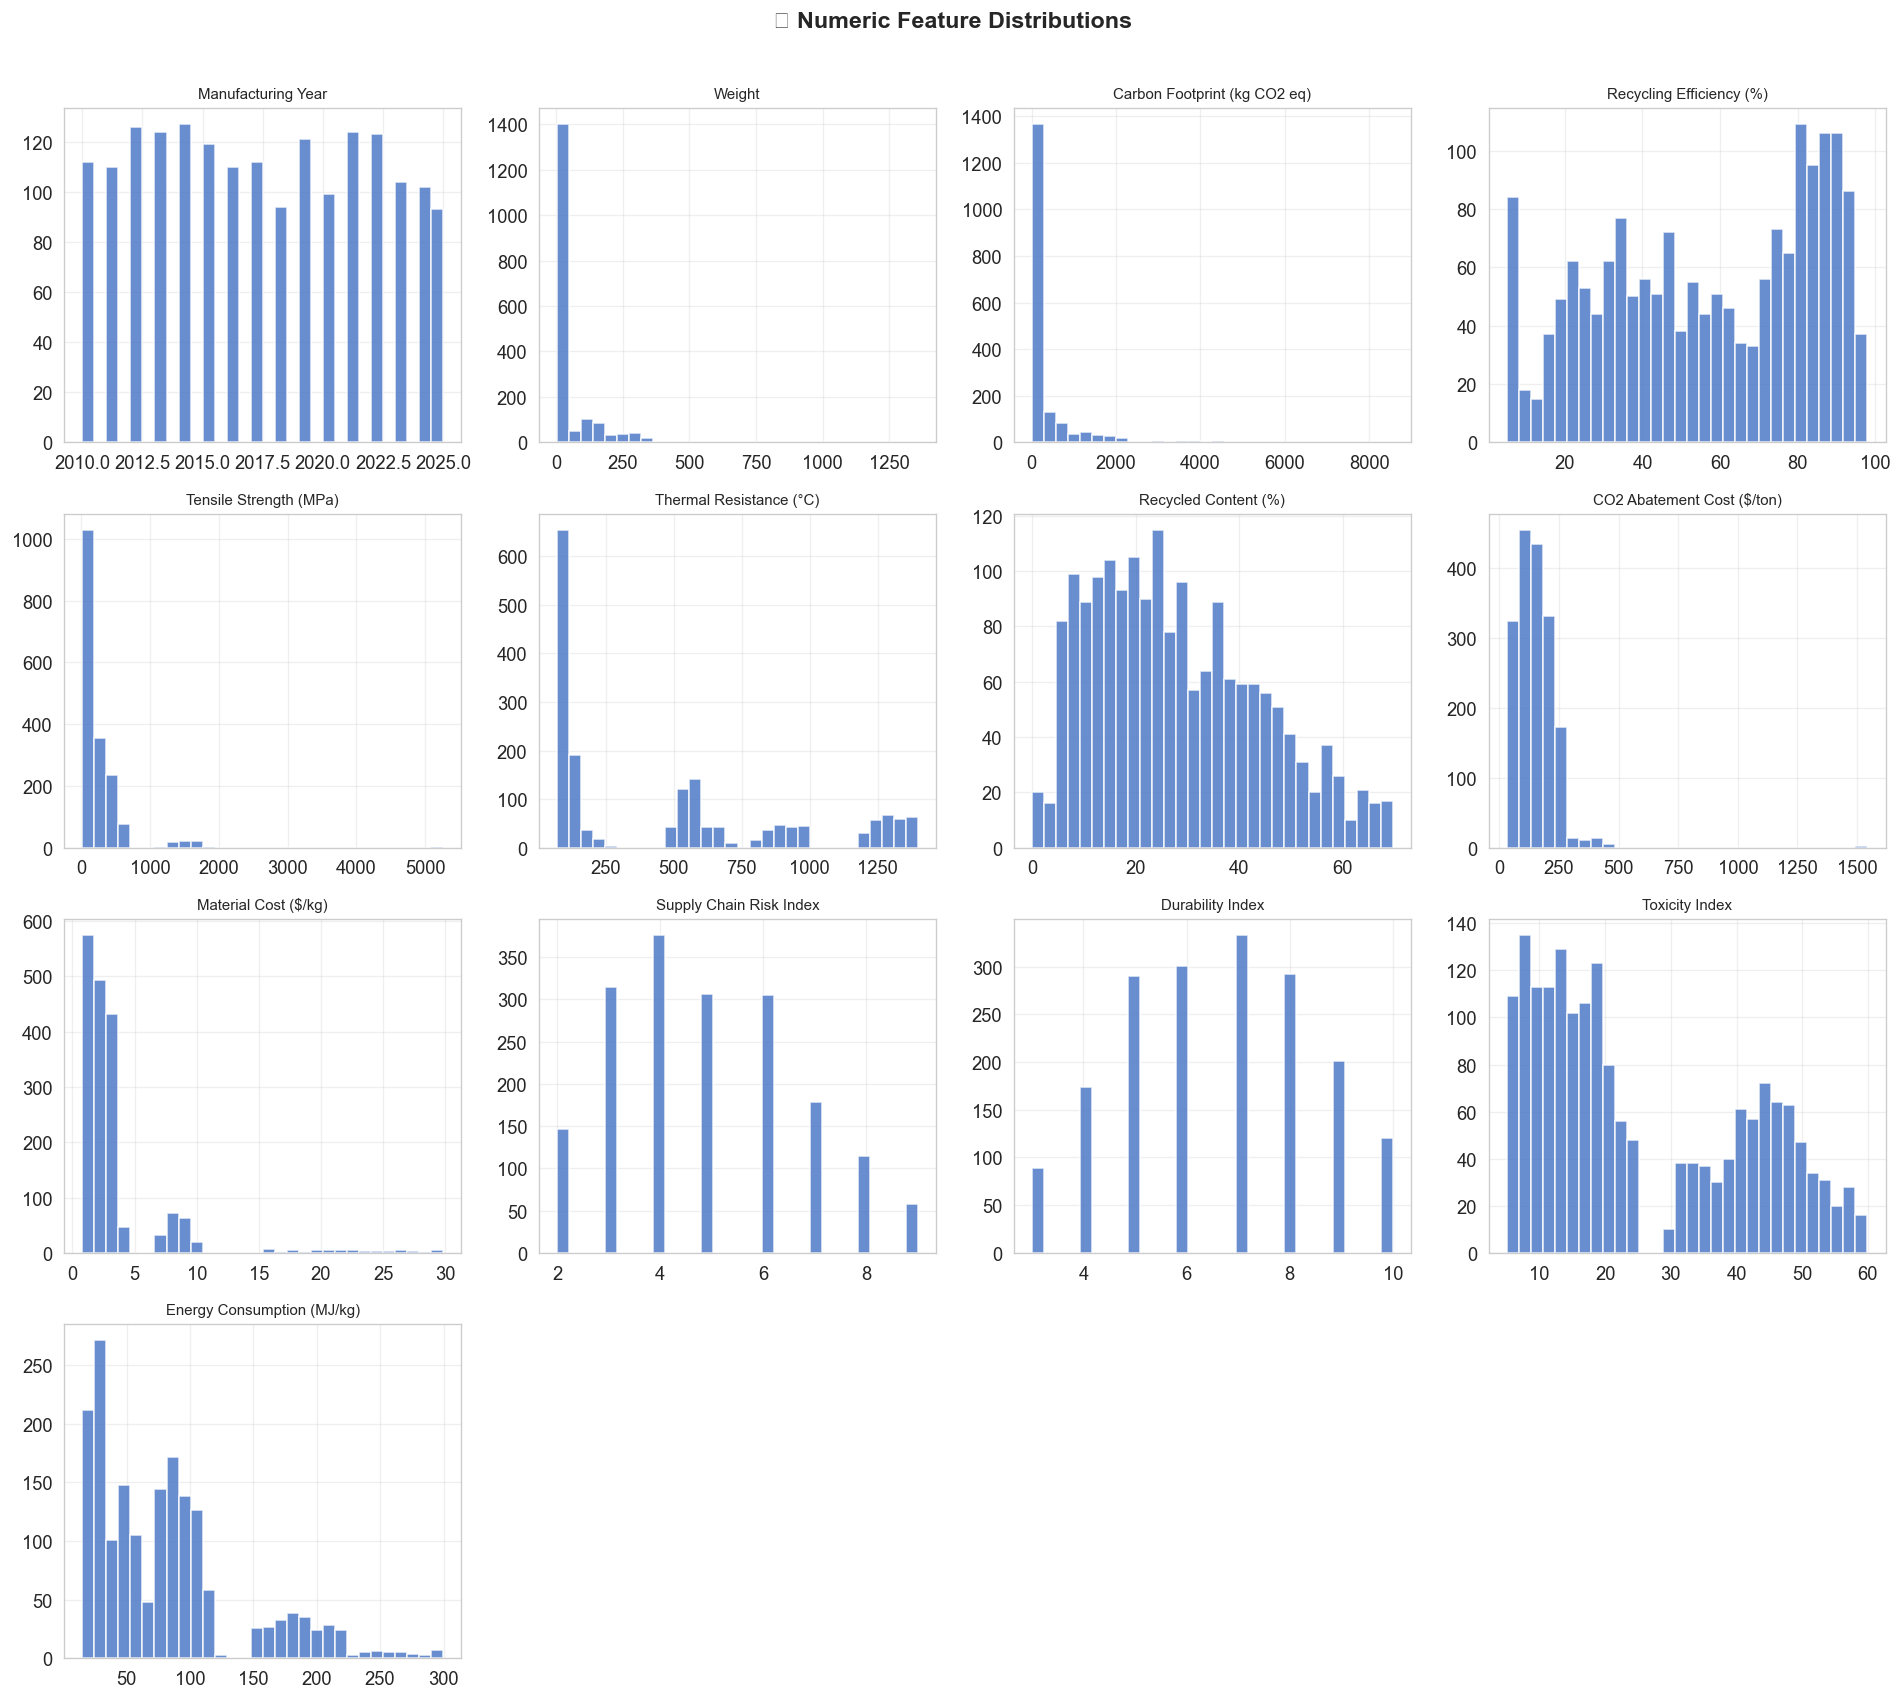

In [9]:
# 2g. Numeric feature histograms
num_cols = df_raw.select_dtypes(include=np.number).columns.tolist()
n = len(num_cols)
ncols = 4
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(16, nrows * 3.5))
axes_flat = axes.flatten()

for i, col in enumerate(num_cols):
    axes_flat[i].hist(df_raw[col].dropna(), bins=30, color='#4472C4', edgecolor='white', alpha=0.8)
    axes_flat[i].set_title(col, fontsize=9)

for j in range(i+1, len(axes_flat)):
    axes_flat[j].set_visible(False)

plt.suptitle('📊 Numeric Feature Distributions', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

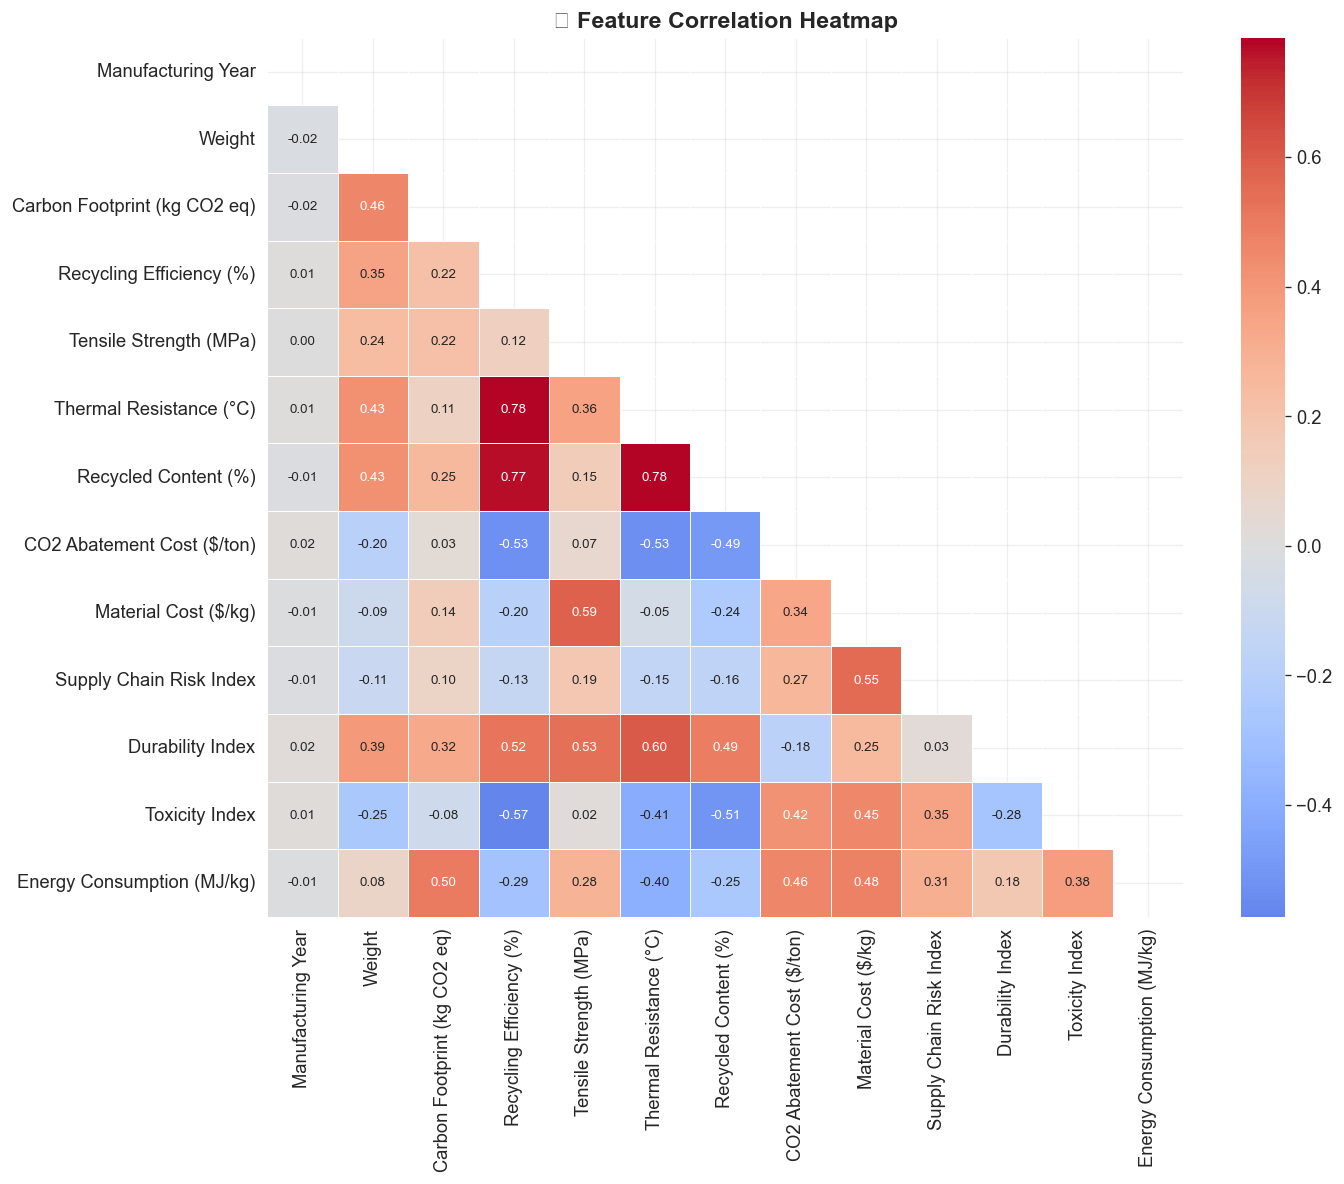

In [10]:
# 2h. Correlation heatmap
corr = df_raw[num_cols].corr()
fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, ax=ax, annot_kws={'size': 8})
ax.set_title('🔗 Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [11]:
# 2i. Duplicates & Outliers (IQR)
dups = df_raw.duplicated().sum()
print(f'Duplicate rows: {dups}')

print('\nOutlier counts per numeric column (IQR method):')
outlier_counts = {}
for col in num_cols:
    Q1 = df_raw[col].quantile(0.25)
    Q3 = df_raw[col].quantile(0.75)
    IQR = Q3 - Q1
    n_out = ((df_raw[col] < Q1 - 1.5*IQR) | (df_raw[col] > Q3 + 1.5*IQR)).sum()
    outlier_counts[col] = n_out

out_s = pd.Series(outlier_counts).sort_values(ascending=False)
print(out_s[out_s > 0].to_string())

Duplicate rows: 0

Outlier counts per numeric column (IQR method):
Weight                          339
Carbon Footprint (kg CO2 eq)    304
Material Cost ($/kg)            252
Energy Consumption (MJ/kg)       90
Tensile Strength (MPa)           67
CO2 Abatement Cost ($/ton)       27


---
## 🧹 Cell 3 — Preprocessing & Cleaning

In [12]:
# Drop rows with any NaN (evaluator feedback: remove missing rows)
df = df_raw.dropna().reset_index(drop=True)

rows_dropped = len(df_raw) - len(df)
print(f'Rows before : {len(df_raw):,}')
print(f'Rows dropped: {rows_dropped:,}  ({rows_dropped/len(df_raw)*100:.1f}%)')
print(f'Rows after  : {len(df):,}')

assert df.isnull().sum().sum() == 0, '❌ NaN still present!'
print('\n✅ Zero missing values after cleaning')

Rows before : 1,800
Rows dropped: 201  (11.2%)
Rows after  : 1,599

✅ Zero missing values after cleaning


---
## 🔢 Cell 4 — Feature Encoding

In [13]:
categorical_cols = [
    'Material Name', 'Vehicle Type', 'Component',
    'Hazardous Level', 'Material Condition', 'Corrosion Resistance'
]
target_col = 'Target'

encoders = {}
df_enc = df.copy()

for col in categorical_cols:
    le = LabelEncoder()
    df_enc[col] = le.fit_transform(df_enc[col])
    encoders[col] = dict(zip(le.classes_, le.transform(le.classes_).tolist()))
    print(f'{col}: {encoders[col]}')

target_encoder = LabelEncoder()
y_all = target_encoder.fit_transform(df_enc[target_col])
class_names = list(target_encoder.classes_)
print(f'\nTarget classes → {dict(zip(class_names, range(len(class_names))))}')

feature_cols = [c for c in df_enc.columns if c != target_col]
X_all = df_enc[feature_cols].values
print(f'\nFeature matrix: {X_all.shape}  |  Target vector: {y_all.shape}')

Material Name: {'Acrylonitrile Butadiene Styrene (ABS)': 0, 'Aluminum Alloy (6061)': 1, 'Carbon Fiber Reinforced Polymer (CFRP)': 2, 'Copper Alloy': 3, 'Glass': 4, 'Natural Rubber': 5, 'Polyethylene (HDPE)': 6, 'Polypropylene (PP)': 7, 'Polyurethane (PU)': 8, 'Structural Steel': 9}
Vehicle Type: {'Electric': 0, 'Hybrid': 1, 'ICE': 2}
Component: {'Body Panels': 0, 'Bumper': 1, 'Chassis': 2, 'Dashboard': 3, 'Engine Block': 4, 'Fuel Tank': 5, 'Seat Foam': 6, 'Tires': 7, 'Windshield': 8, 'Wiring Harness': 9}
Hazardous Level: {'High': 0, 'Low': 1, 'Medium': 2}
Material Condition: {'Excellent': 0, 'Fair': 1, 'Good': 2, 'Poor': 3}
Corrosion Resistance: {'High': 0, 'Medium': 1}

Target classes → {'Dispose': 0, 'Recycle': 1, 'Reuse': 2}

Feature matrix: (1599, 19)  |  Target vector: (1599,)


---
## ✂️ Cell 5 — Dataset Split (70% Train / 20% Test / 10% Validation)

In [14]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X_all, y_all, test_size=0.30, random_state=RANDOM_STATE, stratify=y_all
)
X_test, X_val, y_test, y_val = train_test_split(
    X_temp, y_temp, test_size=(10/30), random_state=RANDOM_STATE, stratify=y_temp
)

total = len(X_all)
print('Split summary:')
print(f'  Train:      {len(X_train):4d}  ({len(X_train)/total:.1%})')
print(f'  Test:       {len(X_test):4d}  ({len(X_test)/total:.1%})')
print(f'  Validation: {len(X_val):4d}  ({len(X_val)/total:.1%})')
print(f'  Total:      {total:4d}')

print('\nClass distribution per split:')
for name, y in [('Train', y_train), ('Test', y_test), ('Validation', y_val)]:
    counts = np.bincount(y)
    pcts = counts / len(y) * 100
    row = '  |  '.join([f'{class_names[i]}: {counts[i]} ({pcts[i]:.1f}%)' for i in range(len(class_names))])
    print(f'  {name:12s}: {row}')
print('\n✅ Stratified split complete')

Split summary:
  Train:      1119  (70.0%)
  Test:        320  (20.0%)
  Validation:  160  (10.0%)
  Total:      1599

Class distribution per split:
  Train       : Dispose: 228 (20.4%)  |  Recycle: 503 (45.0%)  |  Reuse: 388 (34.7%)
  Test        : Dispose: 65 (20.3%)  |  Recycle: 144 (45.0%)  |  Reuse: 111 (34.7%)
  Validation  : Dispose: 33 (20.6%)  |  Recycle: 72 (45.0%)  |  Reuse: 55 (34.4%)

✅ Stratified split complete


---
## 🤖 Cell 6A — Model 1: Random Forest (with GridSearchCV)

In [15]:
print('Training Random Forest with GridSearchCV...')
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [8, 12, None],
    'min_samples_split': [2, 5],
}
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    rf_param_grid, cv=3, scoring='accuracy', n_jobs=-1, verbose=0
)
rf_grid.fit(X_train, y_train)
best_rf = rf_grid.best_estimator_

print(f'Best RF params: {rf_grid.best_params_}')
print(f'CV best score:  {rf_grid.best_score_:.4f}')

val_pred_rf  = best_rf.predict(X_val)
val_proba_rf = best_rf.predict_proba(X_val)
rf_metrics = {
    'best_params':   rf_grid.best_params_,
    'val_accuracy':  accuracy_score(y_val, val_pred_rf),
    'val_loss':      log_loss(y_val, val_proba_rf),
    'val_precision': precision_score(y_val, val_pred_rf, average='macro'),
    'val_recall':    recall_score(y_val, val_pred_rf, average='macro'),
    'val_f1':        f1_score(y_val, val_pred_rf, average='macro'),
}
print(f'Val accuracy: {rf_metrics["val_accuracy"]:.4f}  |  Val loss: {rf_metrics["val_loss"]:.4f}  |  Val F1: {rf_metrics["val_f1"]:.4f}')

Training Random Forest with GridSearchCV...


Best RF params: {'max_depth': 8, 'min_samples_split': 2, 'n_estimators': 100}
CV best score:  0.5684
Val accuracy: 0.5437  |  Val loss: 0.8877  |  Val F1: 0.4993


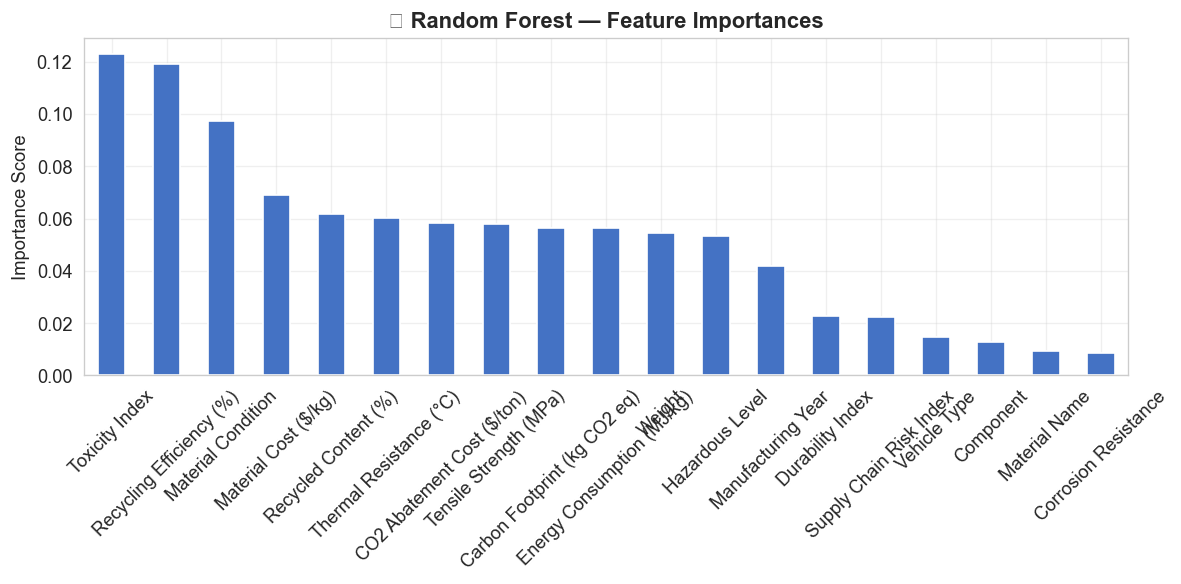

✅ Saved rf_feature_importance.png


In [16]:
# Feature importances
feat_imp = pd.Series(best_rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
feat_imp.plot(kind='bar', ax=ax, color='#4472C4', edgecolor='white')
ax.set_title('🌲 Random Forest — Feature Importances', fontweight='bold')
ax.set_ylabel('Importance Score')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'rf_feature_importance.png'), dpi=150)
plt.show()
print('✅ Saved rf_feature_importance.png')

---
## 📈 Cell 6A-2 — Random Forest "Epoch" Curve (30 rounds, via `warm_start`)

Random Forest builds trees independently (bagging), so it has no native per-epoch loss like XGBoost's boosting rounds. 
To get a comparable training curve, we use `warm_start=True` and add one tree at a time (1 → 30 trees), 
recording train/validation accuracy and log-loss after each addition — same best hyperparameters as the tuned model above.

In [ ]:
N_EPOCHS = 30

rf_epoch = RandomForestClassifier(
    n_estimators=1,
    max_depth=rf_grid.best_params_['max_depth'],
    min_samples_split=rf_grid.best_params_['min_samples_split'],
    random_state=RANDOM_STATE,
    warm_start=True,
)

train_acc_curve, val_acc_curve = [], []
train_loss_curve, val_loss_curve = [], []

for epoch in range(1, N_EPOCHS + 1):
    rf_epoch.n_estimators = epoch
    rf_epoch.fit(X_train, y_train)

    train_proba = rf_epoch.predict_proba(X_train)
    val_proba   = rf_epoch.predict_proba(X_val)

    train_acc_curve.append(accuracy_score(y_train, rf_epoch.predict(X_train)))
    val_acc_curve.append(accuracy_score(y_val, rf_epoch.predict(X_val)))
    train_loss_curve.append(log_loss(y_train, train_proba, labels=np.unique(y_all)))
    val_loss_curve.append(log_loss(y_val, val_proba, labels=np.unique(y_all)))

epochs_range = range(1, N_EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(epochs_range, train_loss_curve, label='Train Loss')
axes[0].plot(epochs_range, val_loss_curve, label='Validation Loss')
axes[0].set_xlabel('Epoch (Trees Added)')
axes[0].set_ylabel('Log Loss')
axes[0].set_title('Random Forest Loss Curve (30 Epochs)')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, train_acc_curve, label='Train Accuracy')
axes[1].plot(epochs_range, val_acc_curve, label='Validation Accuracy')
axes[1].set_xlabel('Epoch (Trees Added)')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Random Forest Accuracy Curve (30 Epochs)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'rf_training_curves.png'), dpi=150)
plt.show()

print(f'Final (epoch {N_EPOCHS}) — Train acc: {train_acc_curve[-1]:.4f}  |  Val acc: {val_acc_curve[-1]:.4f}')
print(f'Final (epoch {N_EPOCHS}) — Train loss: {train_loss_curve[-1]:.4f}  |  Val loss: {val_loss_curve[-1]:.4f}')
print('✅ Saved rf_training_curves.png')


---
## 🤖 Cell 6B — Model 2: XGBoost (Epoch / LR / Val-loss tracking)

In [17]:
print('Training XGBoost with GridSearchCV...')
xgb_param_grid = {
    'n_estimators': [30],
    'learning_rate': [0.05, 0.1, 0.2],
    'max_depth': [4, 6],
}
xgb_grid = GridSearchCV(
    XGBClassifier(objective='multi:softprob', eval_metric='mlogloss',
                  random_state=RANDOM_STATE, use_label_encoder=False),
    xgb_param_grid, cv=3, scoring='accuracy', n_jobs=-1, verbose=0
)
xgb_grid.fit(X_train, y_train)
best_params = xgb_grid.best_params_

print(f'Best XGBoost params: {best_params}')
print(f'CV best score:       {xgb_grid.best_score_:.4f}')

# Retrain with eval_set to capture per-round curves
best_xgb = XGBClassifier(
    n_estimators=best_params['n_estimators'],
    learning_rate=best_params['learning_rate'],
    max_depth=best_params['max_depth'],
    objective='multi:softprob',
    eval_metric=['mlogloss', 'merror'],
    random_state=RANDOM_STATE,
)
best_xgb.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=False,
)
evals_result = best_xgb.evals_result()

val_pred_xgb  = best_xgb.predict(X_val)
val_proba_xgb = best_xgb.predict_proba(X_val)
xgb_metrics = {
    'best_params':   best_params,
    'val_accuracy':  accuracy_score(y_val, val_pred_xgb),
    'val_loss':      log_loss(y_val, val_proba_xgb),
    'val_precision': precision_score(y_val, val_pred_xgb, average='macro'),
    'val_recall':    recall_score(y_val, val_pred_xgb, average='macro'),
    'val_f1':        f1_score(y_val, val_pred_xgb, average='macro'),
}
print(f'Val accuracy: {xgb_metrics["val_accuracy"]:.4f}  |  Val loss: {xgb_metrics["val_loss"]:.4f}  |  Val F1: {xgb_metrics["val_f1"]:.4f}')

Training XGBoost with GridSearchCV...


/Users/srinidhids/Library/Python/3.9/lib/python/site-packages/xgboost/core.py:158: UserWarning: [00:31:45] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/Users/srinidhids/Library/Python/3.9/lib/python/site-packages/xgboost/core.py:158: UserWarning: [00:31:45] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/Users/srinidhids/Library/Python/3.9/lib/python/site-packages/xgboost/core.py:158: UserWarning: [00:31:45] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/Users/srinidhids/Library/Python/3.9/lib/python/site-packages/xgboost/core.py:158: UserWarning: [00:31:45] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  w

/Users/srinidhids/Library/Python/3.9/lib/python/site-packages/xgboost/core.py:158: UserWarning: [00:31:45] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/Users/srinidhids/Library/Python/3.9/lib/python/site-packages/xgboost/core.py:158: UserWarning: [00:31:45] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Best XGBoost params: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 150}
CV best score:       0.5746


Val accuracy: 0.5500  |  Val loss: 0.8820  |  Val F1: 0.4780


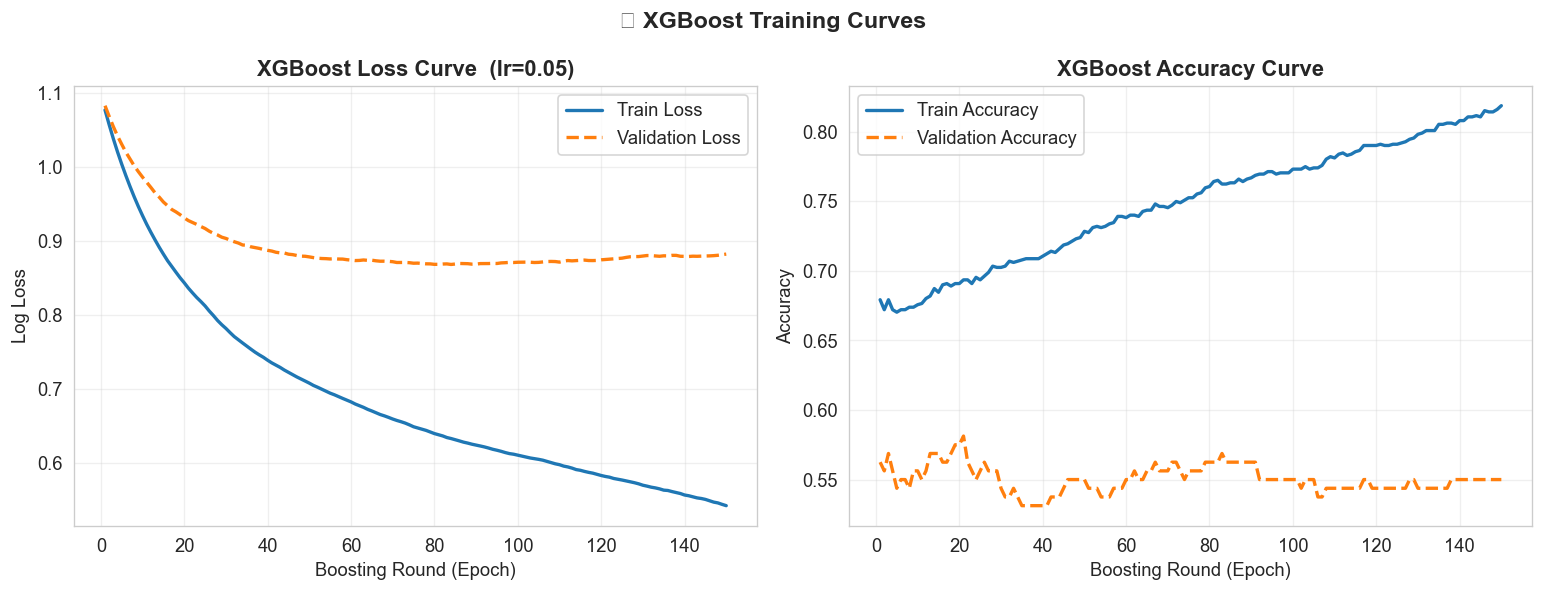

✅ Saved xgboost_training_curves.png


In [18]:
# Training curves plot
epochs = range(1, len(evals_result['validation_0']['mlogloss']) + 1)
train_acc_curve = [1 - e for e in evals_result['validation_0']['merror']]
val_acc_curve   = [1 - e for e in evals_result['validation_1']['merror']]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(epochs, evals_result['validation_0']['mlogloss'], label='Train Loss', lw=2)
axes[0].plot(epochs, evals_result['validation_1']['mlogloss'], label='Validation Loss', lw=2, ls='--')
axes[0].set_xlabel('Boosting Round (Epoch)')
axes[0].set_ylabel('Log Loss')
axes[0].set_title(f'XGBoost Loss Curve  (lr={best_params["learning_rate"]})', fontweight='bold')
axes[0].legend()

axes[1].plot(epochs, train_acc_curve, label='Train Accuracy', lw=2)
axes[1].plot(epochs, val_acc_curve,   label='Validation Accuracy', lw=2, ls='--')
axes[1].set_xlabel('Boosting Round (Epoch)')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('XGBoost Accuracy Curve', fontweight='bold')
axes[1].legend()

plt.suptitle('📈 XGBoost Training Curves', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'xgboost_training_curves.png'), dpi=150)
plt.show()
print('✅ Saved xgboost_training_curves.png')

---
## 🤖 Cell 6C — Model 3: SVM (Baseline)

In [19]:
print('Training SVM (RBF kernel)...')
svm = SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE)
svm.fit(X_train, y_train)

val_pred_svm  = svm.predict(X_val)
val_proba_svm = svm.predict_proba(X_val)
svm_metrics = {
    'best_params':   {'kernel': 'rbf'},
    'val_accuracy':  accuracy_score(y_val, val_pred_svm),
    'val_loss':      log_loss(y_val, val_proba_svm),
    'val_precision': precision_score(y_val, val_pred_svm, average='macro'),
    'val_recall':    recall_score(y_val, val_pred_svm, average='macro'),
    'val_f1':        f1_score(y_val, val_pred_svm, average='macro'),
}
print(f'Val accuracy: {svm_metrics["val_accuracy"]:.4f}  |  Val loss: {svm_metrics["val_loss"]:.4f}  |  Val F1: {svm_metrics["val_f1"]:.4f}')

Training SVM (RBF kernel)...
Val accuracy: 0.4313  |  Val loss: 1.0380  |  Val F1: 0.2371


---
## 🤖 Cell 6D — Model 4: Hybrid Stacking Ensemble

In [20]:
print('Training Hybrid Stacking Ensemble (RF + XGBoost → LR meta-learner)...')
hybrid = StackingClassifier(
    estimators=[
        ('rf',  RandomForestClassifier(**rf_grid.best_params_, random_state=RANDOM_STATE)),
        ('xgb', XGBClassifier(**best_params, objective='multi:softprob',
                               eval_metric='mlogloss', random_state=RANDOM_STATE)),
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=3,
)
hybrid.fit(X_train, y_train)

val_pred_hybrid  = hybrid.predict(X_val)
val_proba_hybrid = hybrid.predict_proba(X_val)
hybrid_metrics = {
    'best_params':   'RF + XGBoost base learners, Logistic Regression meta-learner',
    'val_accuracy':  accuracy_score(y_val, val_pred_hybrid),
    'val_loss':      log_loss(y_val, val_proba_hybrid),
    'val_precision': precision_score(y_val, val_pred_hybrid, average='macro'),
    'val_recall':    recall_score(y_val, val_pred_hybrid, average='macro'),
    'val_f1':        f1_score(y_val, val_pred_hybrid, average='macro'),
}
print(f'Val accuracy: {hybrid_metrics["val_accuracy"]:.4f}  |  Val loss: {hybrid_metrics["val_loss"]:.4f}  |  Val F1: {hybrid_metrics["val_f1"]:.4f}')

Training Hybrid Stacking Ensemble (RF + XGBoost → LR meta-learner)...


Val accuracy: 0.5687  |  Val loss: 0.8728  |  Val F1: 0.4257


---
## 📊 Cell 7 — Model Comparison

In [21]:
results = {
    'Random Forest':                rf_metrics,
    'XGBoost':                      xgb_metrics,
    'SVM':                          svm_metrics,
    'Hybrid (RF + XGBoost Stacked)': hybrid_metrics,
}

comp_df = pd.DataFrame(results).T[['val_accuracy', 'val_loss', 'val_precision', 'val_recall', 'val_f1']]
comp_df.columns = ['Val Accuracy', 'Val Loss', 'Val Precision', 'Val Recall', 'Val F1']

print('=' * 70)
print('VALIDATION SET RESULTS — MODEL COMPARISON')
print('=' * 70)
display(comp_df.round(4))

best_model_name = comp_df['Val Accuracy'].idxmax()
print(f'\n🏆 Best model: "{best_model_name}"')
print(f'   Val Accuracy = {comp_df.loc[best_model_name, "Val Accuracy"]:.4f}')

VALIDATION SET RESULTS — MODEL COMPARISON


,Val Accuracy,Val Loss,Val Precision,Val Recall,Val F1
Random Forest,0.54375,0.887683,0.540643,0.508081,0.499312
XGBoost,0.55,0.88198,0.491618,0.500589,0.477958
SVM,0.43125,1.037954,0.249956,0.325168,0.237085
Hybrid (RF + XGBoost Stacked),0.56875,0.872794,0.380369,0.484259,0.425702



🏆 Best model: "Hybrid (RF + XGBoost Stacked)"
   Val Accuracy = 0.5687


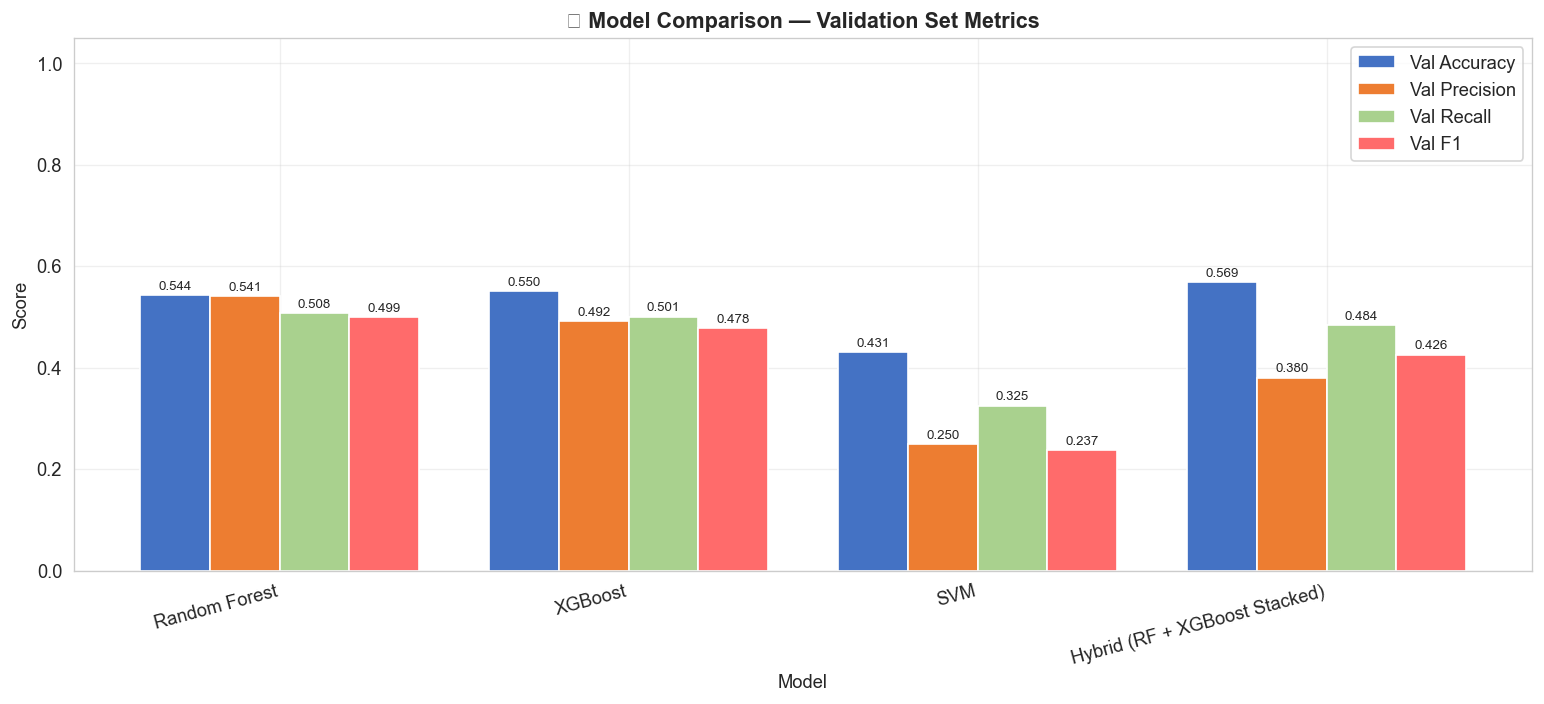

✅ Saved model_comparison.png


In [22]:
# Grouped bar chart
metrics_to_plot = ['Val Accuracy', 'Val Precision', 'Val Recall', 'Val F1']
x = np.arange(len(comp_df))
width = 0.2
palette = ['#4472C4', '#ED7D31', '#A9D18E', '#FF6B6B']

fig, ax = plt.subplots(figsize=(13, 6))
for i, metric in enumerate(metrics_to_plot):
    bars = ax.bar(x + i*width, comp_df[metric], width, label=metric, color=palette[i], edgecolor='white')
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., h + 0.005,
                f'{h:.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xlabel('Model')
ax.set_ylabel('Score')
ax.set_title('🏆 Model Comparison — Validation Set Metrics', fontsize=13, fontweight='bold')
ax.set_xticks(x + width*1.5)
ax.set_xticklabels(comp_df.index, rotation=15, ha='right')
ax.set_ylim(0, 1.05)
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'model_comparison.png'), dpi=150)
plt.show()
print('✅ Saved model_comparison.png')

---
## 🎯 Cell 8 — Final Test-Set Evaluation of Best Model

In [23]:
model_lookup = {
    'Random Forest':                best_rf,
    'XGBoost':                      best_xgb,
    'SVM':                          svm,
    'Hybrid (RF + XGBoost Stacked)': hybrid,
}

final_model = model_lookup[best_model_name]
test_pred   = final_model.predict(X_test)
test_acc    = accuracy_score(y_test, test_pred)

print(f'🏆 Best model: {best_model_name}')
print(f'   Test Accuracy: {test_acc:.4f}  ({test_acc*100:.2f}%)')
print()
print('Classification Report (held-out test set):')
print(classification_report(y_test, test_pred, target_names=class_names))

🏆 Best model: Hybrid (RF + XGBoost Stacked)
   Test Accuracy: 0.5844  (58.44%)

Classification Report (held-out test set):
              precision    recall  f1-score   support

     Dispose       0.00      0.00      0.00        65
     Recycle       0.55      0.73      0.62       144
       Reuse       0.64      0.74      0.69       111

    accuracy                           0.58       320
   macro avg       0.40      0.49      0.44       320
weighted avg       0.47      0.58      0.52       320



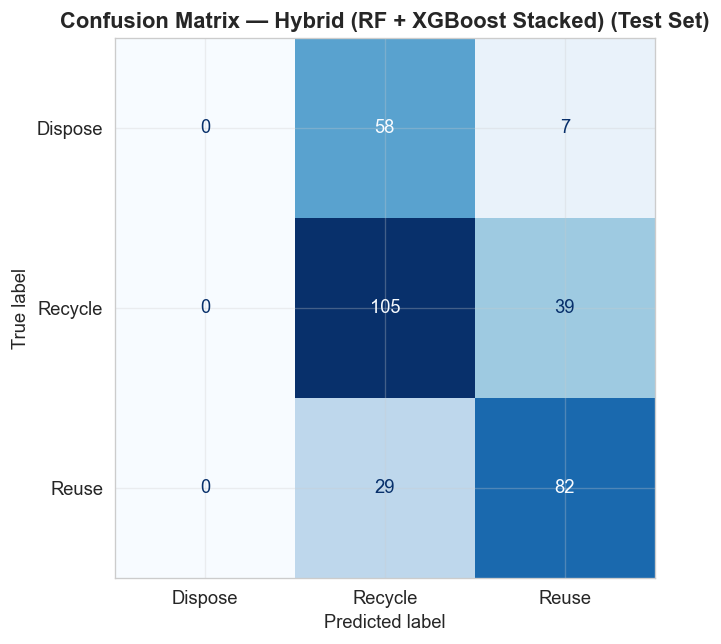

✅ Saved confusion_matrix.png


In [24]:
# Confusion matrix
cm = confusion_matrix(y_test, test_pred)
fig, ax = plt.subplots(figsize=(6, 5.5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Confusion Matrix — {best_model_name} (Test Set)', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'confusion_matrix.png'), dpi=150)
plt.show()
print('✅ Saved confusion_matrix.png')

---
## 💾 Cell 9 — Save Results Summary

In [25]:
def to_serializable(v):
    if isinstance(v, (np.floating, np.float32, np.float64)):
        return float(v)
    if isinstance(v, (np.integer,)):
        return int(v)
    return v

summary = {
    'dataset_rows_raw':            len(df_raw),
    'dataset_rows_after_cleaning': len(df),
    'rows_dropped_missing':        len(df_raw) - len(df),
    'split': {'train': len(X_train), 'test': len(X_test), 'validation': len(X_val)},
    'results': {k: {kk: to_serializable(vv) for kk, vv in v.items()} for k, v in results.items()},
    'best_model':              best_model_name,
    'best_model_test_accuracy': float(test_acc),
}

out_path = os.path.join(RESULTS_DIR, 'results_summary.json')
with open(out_path, 'w') as f:
    json.dump(summary, f, indent=2, default=str)

print(f'✅ Saved results_summary.json → {os.path.abspath(out_path)}')
print('\nResults saved to ../results/ folder:')
for fname in os.listdir(RESULTS_DIR):
    fpath = os.path.join(RESULTS_DIR, fname)
    size_kb = os.path.getsize(fpath) / 1024
    print(f'  {fname:<45s}  {size_kb:.1f} KB')

✅ Saved results_summary.json → /Users/srinidhids/PROJECTS/MAJOR-PROJECT---52/results/results_summary.json

Results saved to ../results/ folder:
  confusion_matrix.png                           37.8 KB
  xgboost_training_curves.png                    107.3 KB
  results_summary.json                           1.5 KB
  rf_feature_importance.png                      121.9 KB
  model_comparison.png                           70.0 KB


---
## ✅ Cell 10 — Pipeline Complete — Summary

| Step | Details |
|------|---------|
| Dataset | `automotive_material_lifecycle_dataset.csv` |
| Target | `Target` (Dispose / Recycle / Reuse) |
| Preprocessing | Drop NaN rows, Label Encode categoricals |
| Split | 70% Train / 20% Test / 10% Validation (stratified) |
| Models | Random Forest, XGBoost, SVM, Hybrid Stacking |
| Tuning | GridSearchCV (3-fold CV) for RF and XGBoost |
| Epoch tracking | XGBoost mlogloss + merror per boosting round |
| Output files | `results_summary.json`, `confusion_matrix.png`, `model_comparison.png`, `xgboost_training_curves.png`, `rf_feature_importance.png` |
| Output folder | `../results/` |